# Exoplanet Classification with K-Nearest Neighbors (K-NN)

**ML Theory Assignment – K-NN on a real-life example**

**Real-life problem:** NASA's Kepler telescope flagged thousands of "Kepler Objects of Interest" (KOIs) – stars whose brightness dips as if a planet were passing in front. Many of these dips are *not* planets (eclipsing binary stars, instrument artifacts). Astronomers cannot follow up on everything, so a model that separates **real planets** from **false positives** helps decide what to study first.

**Task:** binary classification – `CONFIRMED` planet (1) vs `FALSE POSITIVE` (0), using physical measurements of the transit signal, the planet and its star.

**Dataset:** NASA Exoplanet Archive – *Kepler Objects of Interest Cumulative Table* (DOI 10.26133/NEA4). A copy is also on Kaggle ("NASA Exoplanet Dataset", by arashnic).

**Pipeline:** load → clean & avoid leakage → EDA → baselines → baseline K-NN → optimization (k, distance metric, weighting, feature ablation, PCA) → overfitting/underfitting analysis → final test evaluation → **K-NN spotlight** (from-scratch implementation, decision boundaries, neighbor-based explanations, weaknesses, search speed) → predictions for unresolved candidates.

## 1. Setup

In [1]:
import io, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, validation_curve, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay, f1_score, accuracy_score,
                             precision_score, recall_score, roc_auc_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Load the data

The notebook first tries to download the table directly from the NASA Exoplanet Archive. If that fails (no internet, archive busy), it looks for a local CSV (for example the Kaggle file), and finally asks you to upload one.

In [2]:
NASA_URL = ("https://exoplanetarchive.ipac.caltech.edu/TAP/sync"
            "?query=select+*+from+cumulative&format=csv")
LOCAL_CANDIDATES = ["cumulative.csv", "exoplanets.csv", "kepler.csv", "koi.csv"]

def load_koi():
    try:
        import requests
        r = requests.get(NASA_URL, timeout=60)
        r.raise_for_status()
        df = pd.read_csv(io.StringIO(r.text))
        print("Loaded from NASA Exoplanet Archive.")
        return df
    except Exception as e:
        print("Direct download failed:", type(e).__name__)
    for name in LOCAL_CANDIDATES:
        if os.path.exists(name):
            print("Loaded local file:", name)
            return pd.read_csv(name, comment="#")
    try:
        from google.colab import files
        print("Please upload the Kepler KOI CSV (e.g., from Kaggle).")
        up = files.upload()
        return pd.read_csv(io.BytesIO(next(iter(up.values()))), comment="#")
    except Exception as e:
        raise RuntimeError("Could not load the dataset. Upload the CSV next to the notebook.") from e

raw = load_koi()
print(raw.shape)
raw.head()

Loaded from NASA Exoplanet Archive.
(9564, 153)


,kepid,kepoi_name,kepler_name,ra,ra_err,ra_str,dec,dec_err,dec_str,koi_gmag,...,koi_fpflag_co,koi_fpflag_ec,koi_insol,koi_insol_err1,koi_insol_err2,koi_srho,koi_srho_err1,koi_srho_err2,koi_fittype,koi_score
0,10797460,K00752.01,Kepler-227 b,291.93423,0.0,19h27m44.22s,48.141651,0.0,+48d08m29.9s,15.890,...,0,0,93.59,29.45,-16.65,3.20796,0.33173,-1.09986,LS+MCMC,1.000
1,10797460,K00752.02,Kepler-227 c,291.93423,0.0,19h27m44.22s,48.141651,0.0,+48d08m29.9s,15.890,...,0,0,9.11,2.87,-1.62,3.02368,2.20489,-2.49638,LS+MCMC,0.969
2,10811496,K00753.01,NaN,297.00482,0.0,19h48m01.16s,48.134129,0.0,+48d08m02.9s,15.943,...,0,0,39.30,31.04,-10.49,7.29555,35.03293,-2.75453,LS+MCMC,0.000
3,10848459,K00754.01,NaN,285.53461,0.0,19h02m08.31s,48.285210,0.0,+48d17m06.8s,16.100,...,0,0,891.96,668.95,-230.35,0.22080,0.00917,-0.01837,LS+MCMC,0.000
4,10854555,K00755.01,Kepler-664 b,288.75488,0.0,19h15m01.17s,48.226200,0.0,+48d13m34.3s,16.015,...,0,0,926.16,874.33,-314.24,1.98635,2.71141,-1.74541,LS+MCMC,1.000


## 3. Labels, feature selection and **data-leakage control**

* Only `CONFIRMED` (1) and `FALSE POSITIVE` (0) rows are used to train and evaluate. `CANDIDATE` rows are still unresolved, so we keep them aside and predict them at the end.
* **Leakage:** columns such as `koi_score`, `koi_pdisposition` and the `koi_fpflag_*` flags are *outputs of the vetting process that decides the label*. Using them would make the model look brilliant while learning nothing about physics, so they are **excluded**. Error columns (`*_err1/_err2`), IDs and names are also excluded.

In [3]:
print(raw["koi_disposition"].value_counts(dropna=False))

LEAKY = ["koi_score", "koi_pdisposition", "koi_fpflag_nt", "koi_fpflag_ss",
         "koi_fpflag_co", "koi_fpflag_ec"]

FEATURE_GROUPS = {
    "transit_shape": ["koi_period", "koi_duration", "koi_depth", "koi_impact"],
    "planet":        ["koi_prad", "koi_teq", "koi_insol"],
    "signal":        ["koi_model_snr"],
    "star":          ["koi_steff", "koi_slogg", "koi_srad"],
}
ALL_FEATURES = [c for g in FEATURE_GROUPS.values() for c in g if c in raw.columns]
missing_cols = [c for g in FEATURE_GROUPS.values() for c in g if c not in raw.columns]
print("\nFeatures used:", ALL_FEATURES)
if missing_cols:
    print("Not found in this file (skipped):", missing_cols)
assert not set(ALL_FEATURES) & set(LEAKY)

labeled = raw[raw["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])].copy()
labeled["target"] = (labeled["koi_disposition"] == "CONFIRMED").astype(int)
candidates = raw[raw["koi_disposition"] == "CANDIDATE"].copy()

X = labeled[ALL_FEATURES]
y = labeled["target"]
print(f"\nLabeled rows: {len(labeled)} | planets (1): {y.sum()} | false positives (0): {(y==0).sum()}")
print(f"Unresolved candidates kept aside: {len(candidates)}")

koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2748
CANDIDATE         1977
Name: count, dtype: int64

Features used: ['koi_period', 'koi_duration', 'koi_depth', 'koi_impact', 'koi_prad', 'koi_teq', 'koi_insol', 'koi_model_snr', 'koi_steff', 'koi_slogg', 'koi_srad']

Labeled rows: 7587 | planets (1): 2748 | false positives (0): 4839
Unresolved candidates kept aside: 1977


## 4. Exploratory data analysis

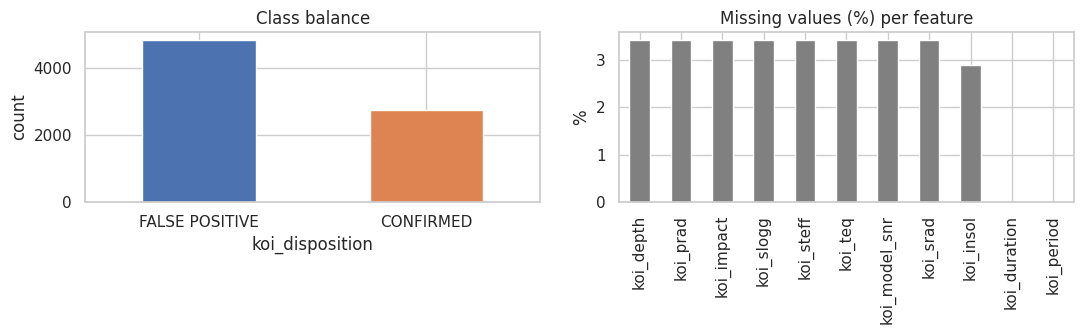

,count,mean,std,min,25%,50%,75%,max
koi_period,7587.0,51.655165,111.824530,0.241843,2.243211,8.088017,30.582145,1.071233e+03
koi_duration,7587.0,5.712962,6.825333,0.104600,2.475650,3.836610,6.272100,1.385400e+02
koi_depth,7328.0,29521.859634,91158.862580,0.800000,182.750000,501.500000,2318.950000,1.541400e+06
koi_impact,7328.0,0.756050,3.195954,0.000000,0.227000,0.586000,0.917000,1.008060e+02
koi_prad,7328.0,104.143442,3180.049778,0.080000,1.500000,2.620000,24.175000,2.003460e+05
koi_teq,7328.0,1154.328466,900.539666,92.000000,581.000000,933.000000,1482.000000,1.466700e+04
koi_insol,7368.0,9389.977013,178161.424379,0.020000,27.215000,180.465000,1151.512500,1.094755e+07
koi_model_snr,7328.0,318.582615,880.976374,0.000000,15.400000,30.500000,114.950000,9.054700e+03
koi_steff,7328.0,5716.201283,819.314206,2661.000000,5313.000000,5774.500000,6117.000000,1.589600e+04
koi_slogg,7328.0,4.310672,0.437269,0.047000,4.217750,4.438000,4.543000,5.283000e+00


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
labeled["koi_disposition"].value_counts().plot.bar(ax=ax[0], color=["#4C72B0", "#DD8452"])
ax[0].set_title("Class balance"); ax[0].set_ylabel("count"); ax[0].tick_params(axis="x", rotation=0)
(X.isna().mean().sort_values(ascending=False) * 100).plot.bar(ax=ax[1], color="gray")
ax[1].set_title("Missing values (%) per feature"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()

X.describe().T

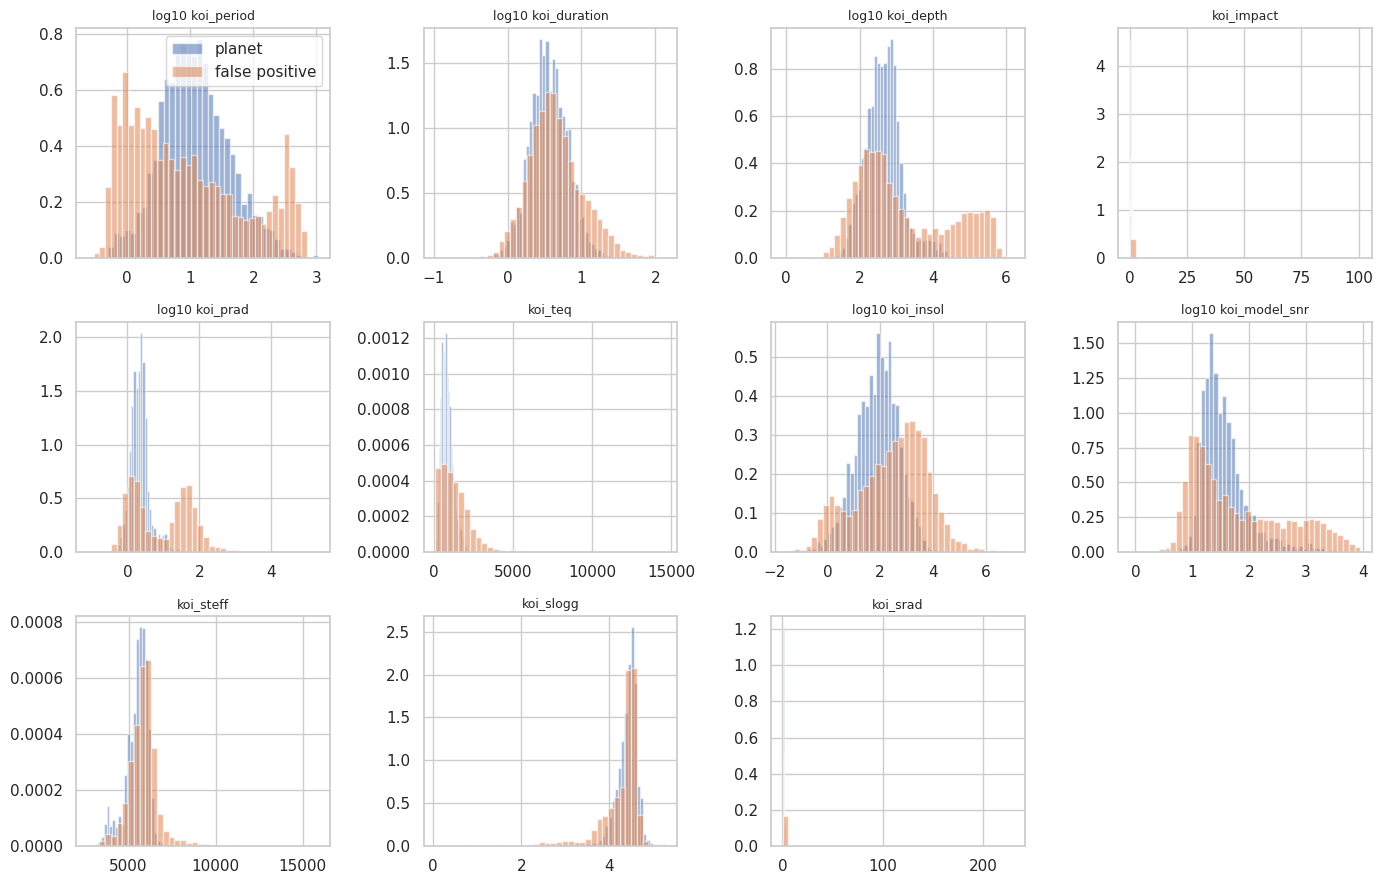

In [5]:
# Feature distributions by class (log scale on x for strongly skewed features)
skewed = [c for c in ["koi_period", "koi_depth", "koi_prad", "koi_insol", "koi_model_snr", "koi_duration"] if c in ALL_FEATURES]
n = len(ALL_FEATURES); cols = 4; rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(14, 3 * rows))
for ax, col in zip(axes.ravel(), ALL_FEATURES):
    for lab, name in [(1, "planet"), (0, "false positive")]:
        v = labeled.loc[labeled["target"] == lab, col].dropna()
        if col in skewed:
            v = v[v > 0]; v = np.log10(v)
        ax.hist(v, bins=40, alpha=0.55, label=name, density=True)
    ax.set_title(("log10 " if col in skewed else "") + col, fontsize=9)
for ax in axes.ravel()[n:]:
    ax.axis("off")
axes.ravel()[0].legend()
plt.tight_layout(); plt.show()

**What to notice:** the two classes overlap strongly in some features and separate in others. That is exactly the situation where K-NN is useful (similar objects have similar labels) and where **scaling and feature choice** matter, because K-NN is distance-based.

## 5. Train / test split

A stratified 80/20 split. The **test set is sealed** – it is used exactly once, at the very end. All tuning uses cross-validation on the training set only.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

(6069, 11) (1518, 11)


## 6. Preprocessing pipeline

Everything is inside a scikit-learn `Pipeline`, so imputation, log transform and scaling are **fitted on the training folds only** (no leakage from validation/test data).

1. Median imputation for missing values.
2. Signed `log1p` for heavy-tailed features (period, depth, radius, insolation, SNR, duration).
3. Standardization (zero mean, unit variance) – essential because K-NN uses distances.

In [7]:
def signed_log1p(a):
    return np.sign(a) * np.log1p(np.abs(a))

LOG_COLS = ["koi_period", "koi_duration", "koi_depth", "koi_prad", "koi_insol", "koi_model_snr"]

def make_preprocessor(features):
    log_cols = [c for c in features if c in LOG_COLS]
    lin_cols = [c for c in features if c not in LOG_COLS]
    parts = []
    if log_cols:
        parts.append(("log", Pipeline([("imp", SimpleImputer(strategy="median")),
                                       ("log", FunctionTransformer(signed_log1p)),
                                       ("sc", StandardScaler())]), log_cols))
    if lin_cols:
        parts.append(("lin", Pipeline([("imp", SimpleImputer(strategy="median")),
                                       ("sc", StandardScaler())]), lin_cols))
    return ColumnTransformer(parts)

def make_knn(features=ALL_FEATURES, k=5, metric="euclidean", weights="uniform", pca=None):
    steps = [("prep", make_preprocessor(features))]
    if pca:
        steps.append(("pca", PCA(n_components=pca, random_state=RANDOM_STATE)))
    steps.append(("knn", KNeighborsClassifier(n_neighbors=k, metric=metric, weights=weights)))
    return Pipeline(steps)

def cv_scores(model, features=ALL_FEATURES):
    res = cross_validate(model, X_train[features], y_train, cv=CV,
                         scoring=["accuracy", "f1", "roc_auc"], n_jobs=-1)
    return {m: res[f"test_{m}"].mean() for m in ["accuracy", "f1", "roc_auc"]}

## 7. Baselines

K-NN only counts as useful if it beats simpler references:
* **Majority class** – always predicts the most common class.
* **Logistic regression** – a simple linear model on the same preprocessed features.

In [8]:
results = {}
results["Majority class"] = cv_scores(Pipeline([("prep", make_preprocessor(ALL_FEATURES)),
                                                 ("clf", DummyClassifier(strategy="most_frequent"))]))
results["Logistic regression"] = cv_scores(Pipeline([("prep", make_preprocessor(ALL_FEATURES)),
                                                      ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]))
results["K-NN baseline (k=5)"] = cv_scores(make_knn())
pd.DataFrame(results).T.round(4)

,accuracy,f1,roc_auc
Majority class,0.6378,0.0000,0.5000
Logistic regression,0.8255,0.7905,0.9095
K-NN baseline (k=5),0.9011,0.8691,0.9542


## 8. Optimization

K-NN has no weights to learn, so "optimization" means choosing the **hyper-parameters and inputs** that generalize best:

| Lever | Why it matters |
|---|---|
| `k` (number of neighbors) | Controls the bias–variance trade-off (see section 9) |
| Distance metric | Euclidean, Manhattan and Chebyshev measure "similar" differently |
| Weighting | `distance` gives closer neighbors more voting power |
| Feature selection | Irrelevant features add noise to the distance |
| PCA | Removes correlated/noisy directions before measuring distance |

### 8.1 Grid search (5-fold stratified CV, scored by F1 of the planet class)

In [9]:
param_grid = {
    "knn__n_neighbors": list(range(1, 52, 2)),
    "knn__metric": ["euclidean", "manhattan", "chebyshev"],
    "knn__weights": ["uniform", "distance"],
}
grid = GridSearchCV(make_knn(), param_grid, cv=CV, scoring="f1", n_jobs=-1, refit=True)
grid.fit(X_train, y_train)
print("Best params:", grid.best_params_)
print("Best CV F1 :", round(grid.best_score_, 4))

gdf = pd.DataFrame(grid.cv_results_)
best_by_metric = (gdf.groupby(["param_knn__metric", "param_knn__weights"])["mean_test_score"].max()
                  .unstack().round(4))
best_by_metric

Best params: {'knn__metric': 'manhattan', 'knn__n_neighbors': 11, 'knn__weights': 'uniform'}
Best CV F1 : 0.8759


param_knn__weights,distance,uniform
param_knn__metric,,
chebyshev,0.8642,0.8624
euclidean,0.8755,0.8751
manhattan,0.8758,0.8759


In [10]:
BEST_K = grid.best_params_["knn__n_neighbors"]
BEST_METRIC = grid.best_params_["knn__metric"]
BEST_WEIGHTS = grid.best_params_["knn__weights"]

### 8.2 Feature ablation – which feature groups actually help?

In [11]:
rows = []
full = cv_scores(make_knn(k=BEST_K, metric=BEST_METRIC, weights=BEST_WEIGHTS))
rows.append(("All features", full["f1"], full["accuracy"]))
for g, cols_ in FEATURE_GROUPS.items():
    cols_ = [c for c in cols_ if c in ALL_FEATURES]
    if not cols_:
        continue
    keep = [c for c in ALL_FEATURES if c not in cols_]
    s = cv_scores(make_knn(keep, BEST_K, BEST_METRIC, BEST_WEIGHTS), keep)
    rows.append((f"Without {g}", s["f1"], s["accuracy"]))
for g, cols_ in FEATURE_GROUPS.items():
    cols_ = [c for c in cols_ if c in ALL_FEATURES]
    if not cols_:
        continue
    s = cv_scores(make_knn(cols_, BEST_K, BEST_METRIC, BEST_WEIGHTS), cols_)
    rows.append((f"Only {g}", s["f1"], s["accuracy"]))
ablation = pd.DataFrame(rows, columns=["Feature set", "CV F1", "CV accuracy"]).round(4)
ablation

,Feature set,CV F1,CV accuracy
0,All features,0.8759,0.9051
1,Without transit_shape,0.8391,0.8791
2,Without planet,0.8509,0.8868
3,Without signal,0.8573,0.8901
4,Without star,0.8609,0.8939
5,Only transit_shape,0.8117,0.8562
6,Only planet,0.7518,0.8155
7,Only signal,0.5722,0.6883
8,Only star,0.5959,0.7184


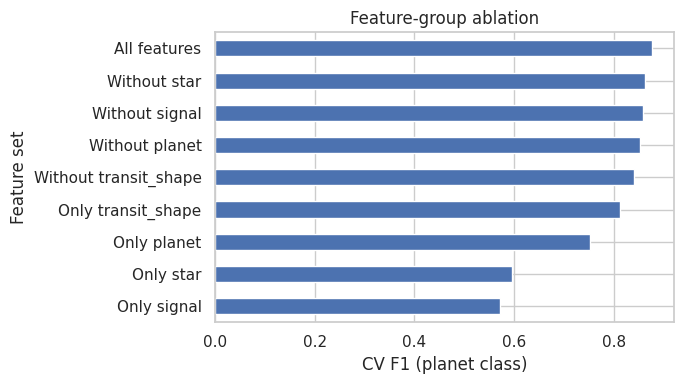

In [12]:
ablation.set_index("Feature set")["CV F1"].sort_values().plot.barh(figsize=(7, 4), color="#4C72B0")
plt.xlabel("CV F1 (planet class)"); plt.title("Feature-group ablation"); plt.tight_layout(); plt.show()

### 8.3 PCA before K-NN

In [13]:
pca_rows = []
for p in [None, 0.99, 0.95, 0.90]:
    s = cv_scores(make_knn(k=BEST_K, metric=BEST_METRIC, weights=BEST_WEIGHTS, pca=p))
    pca_rows.append(("no PCA" if p is None else f"PCA keeps {int(p*100)}% variance", s["f1"], s["accuracy"]))
pd.DataFrame(pca_rows, columns=["Setup", "CV F1", "CV accuracy"]).round(4)

,Setup,CV F1,CV accuracy
0,no PCA,0.8759,0.9051
1,PCA keeps 99% variance,0.8697,0.9005
2,PCA keeps 95% variance,0.8389,0.8797
3,PCA keeps 90% variance,0.8350,0.8769


## 9. Overfitting vs. underfitting analysis

K-NN has no loss function that is minimized iteratively, so instead of a loss curve over epochs we plot the **error rate (zero-one loss = 1 − accuracy)** and **F1** against `k`:

* **Small k** (e.g. 1): the model memorizes training points → training error ≈ 0 but validation error is higher → **overfitting** (high variance).
* **Large k**: predictions are averaged over too many neighbors → both errors rise → **underfitting** (high bias).
* The best `k` sits where the validation curve is at its best.

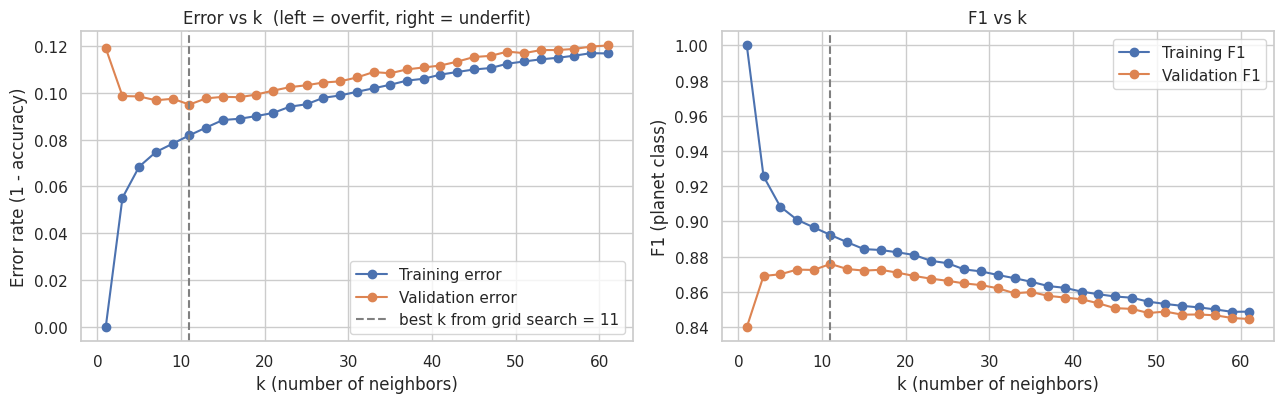

Train–validation accuracy gap at k=1 : 0.119
Train–validation accuracy gap at best k: 0.013


In [14]:
ks = list(range(1, 62, 2))
common = dict(param_name="knn__n_neighbors", param_range=ks, cv=CV, n_jobs=-1)
base = make_knn(metric=BEST_METRIC, weights="uniform")   # 'uniform' so train error at k=1 shows the memorization effect
tr_acc, va_acc = validation_curve(base, X_train, y_train, scoring="accuracy", **common)
tr_f1,  va_f1  = validation_curve(base, X_train, y_train, scoring="f1", **common)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(ks, 1 - tr_acc.mean(1), "o-", label="Training error")
ax[0].plot(ks, 1 - va_acc.mean(1), "o-", label="Validation error")
ax[0].axvline(BEST_K, ls="--", c="gray", label=f"best k from grid search = {BEST_K}")
ax[0].set_xlabel("k (number of neighbors)"); ax[0].set_ylabel("Error rate (1 - accuracy)")
ax[0].set_title("Error vs k  (left = overfit, right = underfit)"); ax[0].legend()

ax[1].plot(ks, tr_f1.mean(1), "o-", label="Training F1")
ax[1].plot(ks, va_f1.mean(1), "o-", label="Validation F1")
ax[1].axvline(BEST_K, ls="--", c="gray")
ax[1].set_xlabel("k (number of neighbors)"); ax[1].set_ylabel("F1 (planet class)")
ax[1].set_title("F1 vs k"); ax[1].legend()
plt.tight_layout(); plt.show()

gap = tr_acc.mean(1) - va_acc.mean(1)
print(f"Train–validation accuracy gap at k=1 : {gap[0]:.3f}")
print(f"Train–validation accuracy gap at best k: {gap[ks.index(BEST_K)] if BEST_K in ks else float('nan'):.3f}")

## 10. Final evaluation on the sealed test set

All models are refit on the full training set and evaluated **once** on the test set.

In [15]:
final_models = {
    "Majority class": Pipeline([("prep", make_preprocessor(ALL_FEATURES)), ("clf", DummyClassifier(strategy="most_frequent"))]),
    "Logistic regression": Pipeline([("prep", make_preprocessor(ALL_FEATURES)), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "K-NN baseline (k=5)": make_knn(),
    "K-NN optimized": make_knn(k=BEST_K, metric=BEST_METRIC, weights=BEST_WEIGHTS),
}
rows = []
for name, m in final_models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    rows.append((name, accuracy_score(y_test, pred), precision_score(y_test, pred, zero_division=0),
                 recall_score(y_test, pred), f1_score(y_test, pred), roc_auc_score(y_test, proba)))
test_table = pd.DataFrame(rows, columns=["Model", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]).set_index("Model").round(4)
test_table

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Majority class,0.6377,0.0000,0.0000,0.0000,0.5000
Logistic regression,0.8353,0.7206,0.8909,0.7967,0.9169
K-NN baseline (k=5),0.9137,0.8606,0.9091,0.8842,0.9630
K-NN optimized,0.9144,0.8535,0.9218,0.8864,0.9684


                precision    recall  f1-score   support

False positive       0.95      0.91      0.93       968
        Planet       0.85      0.92      0.89       550

      accuracy                           0.91      1518
     macro avg       0.90      0.92      0.91      1518
  weighted avg       0.92      0.91      0.92      1518



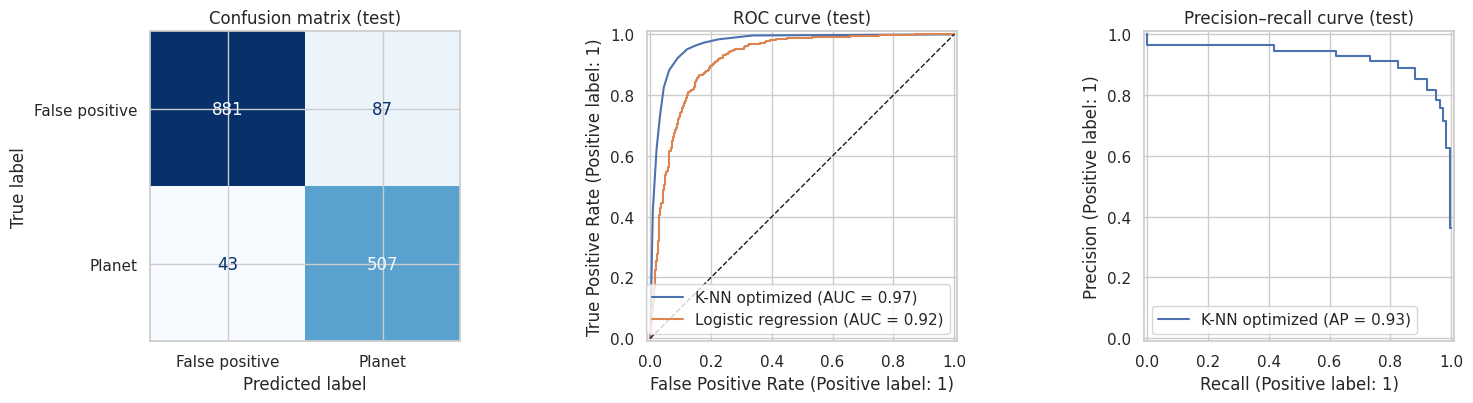

In [16]:
best_model = final_models["K-NN optimized"]
pred = best_model.predict(X_test)
print(classification_report(y_test, pred, target_names=["False positive", "Planet"]))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["False positive", "Planet"]).plot(ax=ax[0], colorbar=False, cmap="Blues")
ax[0].set_title("Confusion matrix (test)")
RocCurveDisplay.from_estimator(best_model, X_test, y_test, ax=ax[1], name="K-NN optimized")
RocCurveDisplay.from_estimator(final_models["Logistic regression"], X_test, y_test, ax=ax[1], name="Logistic regression")
ax[1].plot([0, 1], [0, 1], "k--", lw=1); ax[1].set_title("ROC curve (test)")
PrecisionRecallDisplay.from_estimator(best_model, X_test, y_test, ax=ax[2], name="K-NN optimized")
ax[2].set_title("Precision–recall curve (test)")
plt.tight_layout(); plt.show()

## 11. K-NN spotlight – looking inside the algorithm

The sections above treat K-NN as a model to tune. This section opens it up: we **re-implement it from scratch**, **draw its decision boundary**, **explain individual predictions through their neighbors**, and **test its two classic weaknesses** (scaling and irrelevant features).

### 11.1 K-NN from scratch (NumPy only) vs. scikit-learn

K-NN has no training step: it **stores the data** and, for each new object, (1) computes the distance to every stored object, (2) takes the `k` closest, (3) lets them **vote**. Our implementation does exactly that, then we check it agrees with scikit-learn.

In [17]:
class KNNFromScratch:
    """Binary K-NN with Euclidean distance. predict_proba = share of neighbors that are planets."""
    def __init__(self, k=5, weights="uniform"):
        self.k, self.weights = k, weights

    def fit(self, X, y):                      # "training" = just remember the data
        self.X_ = np.asarray(X, dtype=float)
        self.y_ = np.asarray(y)
        return self

    def kneighbors(self, Xq):
        Xq = np.asarray(Xq, dtype=float)
        # squared Euclidean distance between every query and every stored point
        d2 = (Xq**2).sum(1)[:, None] + (self.X_**2).sum(1)[None, :] - 2 * Xq @ self.X_.T
        dist = np.sqrt(np.maximum(d2, 0))
        idx = np.argsort(dist, axis=1)[:, :self.k]            # the k closest points
        return np.take_along_axis(dist, idx, axis=1), idx

    def predict_proba(self, Xq):
        dist, idx = self.kneighbors(Xq)
        votes = self.y_[idx]                                   # labels of the neighbors
        w = 1 / (dist + 1e-9) if self.weights == "distance" else np.ones_like(dist)
        return (w * votes).sum(1) / w.sum(1)

    def predict(self, Xq):
        return (self.predict_proba(Xq) >= 0.5).astype(int)

prep_s = make_preprocessor(ALL_FEATURES).fit(X_train)
Xtr_s, Xte_s = prep_s.transform(X_train), prep_s.transform(X_test)

mine = KNNFromScratch(k=BEST_K).fit(Xtr_s, y_train.values)
ref = KNeighborsClassifier(n_neighbors=BEST_K, metric="euclidean", weights="uniform").fit(Xtr_s, y_train)

p_mine, p_ref = mine.predict(Xte_s), ref.predict(Xte_s)
print(f"k = {BEST_K}")
print(f"From-scratch accuracy : {accuracy_score(y_test, p_mine):.4f}")
print(f"scikit-learn accuracy : {accuracy_score(y_test, p_ref):.4f}")
print(f"Predictions identical on {(p_mine == p_ref).mean()*100:.2f}% of test objects")

k = 11
From-scratch accuracy : 0.9216
scikit-learn accuracy : 0.9216
Predictions identical on 100.00% of test objects


### 11.2 What does K-NN's decision boundary look like?

K-NN draws its boundary implicitly: every point in space gets the majority label of its nearest stored neighbors. To *see* it we squeeze the 11 features into **2 PCA components** (an illustration only – the real model uses all features).

Watch how the boundary changes with `k`.

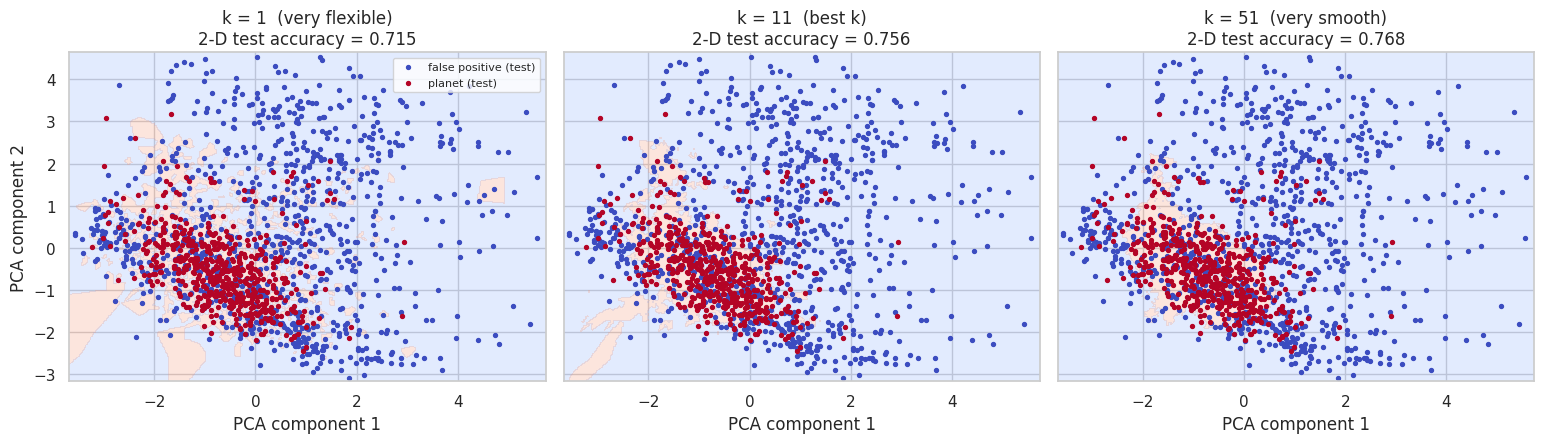

In [18]:
pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit(Xtr_s)
Ztr, Zte = pca2.transform(Xtr_s), pca2.transform(Xte_s)

lo = np.percentile(Ztr, 1, axis=0) - 0.5
hi = np.percentile(Ztr, 99, axis=0) + 0.5
xx, yy = np.meshgrid(np.linspace(lo[0], hi[0], 300), np.linspace(lo[1], hi[1], 300))
grid_pts = np.c_[xx.ravel(), yy.ravel()]

ks_show = sorted({1, BEST_K, 51})
fig, axes = plt.subplots(1, len(ks_show), figsize=(5.2 * len(ks_show), 4.6), sharex=True, sharey=True)
for ax, k in zip(np.atleast_1d(axes), ks_show):
    m = KNeighborsClassifier(n_neighbors=k).fit(Ztr, y_train)
    zz = m.predict(grid_pts).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm", levels=[-0.5, 0.5, 1.5])
    ax.scatter(Zte[y_test == 0, 0], Zte[y_test == 0, 1], s=8, c="#3B4CC0", label="false positive (test)")
    ax.scatter(Zte[y_test == 1, 0], Zte[y_test == 1, 1], s=8, c="#B40426", label="planet (test)")
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])
    tag = "  (best k)" if k == BEST_K else ("  (very flexible)" if k == 1 else "  (very smooth)")
    ax.set_title(f"k = {k}{tag}\n2-D test accuracy = {m.score(Zte, y_test):.3f}")
    ax.set_xlabel("PCA component 1")
np.atleast_1d(axes)[0].set_ylabel("PCA component 2"); np.atleast_1d(axes)[0].legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

**Reading the picture:** with `k = 1` the boundary is jagged and carves islands around single points (**overfitting** – high variance). With a large `k` the boundary becomes smooth and ignores local structure (**underfitting** – high bias). The best `k` is in between. This is the same trade-off as the curve in section 9, now visible in space.

### 11.3 Explaining a prediction through its neighbors

K-NN is one of the few models whose decisions are **directly explainable**: the answer is simply "these are the `k` most similar objects we have seen, and this is how they voted". Below we explain one correctly classified and one misclassified test object. (Neighbors are found in the full 11-feature space and drawn on the 2-D PCA map.)

A correct prediction: true class = planet, predicted = planet; 9 of 11 neighbors are planets (p = 0.82)


,neighbor,its true class,distance
0,K02002.01,planet,0.982
1,K00510.03,planet,0.984
2,K02345.01,planet,1.004
3,K03380.01,false positive,1.038
4,K00664.01,planet,1.060
5,K01276.02,planet,1.073
6,K00516.01,false positive,1.074
7,K02523.01,planet,1.101
8,K01889.02,planet,1.129
9,K01432.02,planet,1.131


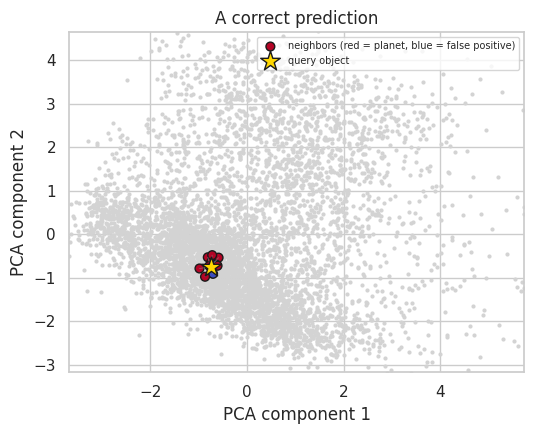

A misclassified object: true class = false positive, predicted = planet; 9 of 11 neighbors are planets (p = 0.82)


,neighbor,its true class,distance
0,K00806.03,planet,0.850
1,K02308.01,planet,1.016
2,K03440.01,planet,1.045
3,K02346.01,planet,1.149
4,K02038.04,planet,1.172
5,K02942.02,planet,1.199
6,K03274.01,planet,1.219
7,K04720.01,false positive,1.222
8,K03300.02,false positive,1.234
9,K01518.01,planet,1.279


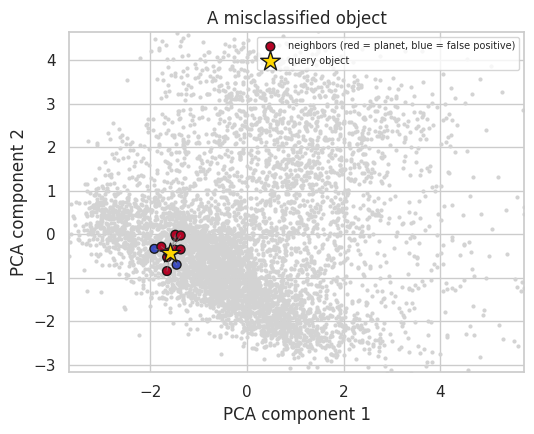

In [19]:
knn_final = final_models["K-NN optimized"]
prep_b, knn_b = knn_final.named_steps["prep"], knn_final.named_steps["knn"]
proba_te = knn_final.predict_proba(X_test)[:, 1]
pred_te = knn_final.predict(X_test)
y_te = y_test.values
name_col = "kepoi_name" if "kepoi_name" in labeled.columns else None

def explain(pos, title):
    xq = prep_b.transform(X_test.iloc[[pos]])
    dist, nn = knn_b.kneighbors(xq)
    dist, nn = dist[0], nn[0]
    nb = X_train.iloc[nn]
    table = pd.DataFrame({
        "neighbor": labeled.loc[nb.index, name_col].values if name_col else nb.index,
        "its true class": np.where(y_train.iloc[nn].values == 1, "planet", "false positive"),
        "distance": dist.round(3)})
    votes = int(y_train.iloc[nn].sum())
    print(f"{title}: true class = {'planet' if y_te[pos]==1 else 'false positive'}, "
          f"predicted = {'planet' if pred_te[pos]==1 else 'false positive'}; "
          f"{votes} of {len(nn)} neighbors are planets (p = {proba_te[pos]:.2f})")
    display(table)
    zq = pca2.transform(xq)
    plt.figure(figsize=(5.5, 4.5))
    plt.scatter(Ztr[:, 0], Ztr[:, 1], s=4, c="lightgray")
    for i in nn:
        plt.plot([zq[0, 0], Ztr[i, 0]], [zq[0, 1], Ztr[i, 1]], c="gray", lw=0.6, alpha=0.7)
    plt.scatter(Ztr[nn, 0], Ztr[nn, 1], s=40, c=np.where(y_train.iloc[nn].values == 1, "#B40426", "#3B4CC0"),
                edgecolor="k", label="neighbors (red = planet, blue = false positive)")
    plt.scatter(zq[:, 0], zq[:, 1], s=220, marker="*", c="gold", edgecolor="k", label="query object", zorder=5)
    plt.xlim(lo[0], hi[0]); plt.ylim(lo[1], hi[1]); plt.title(title); plt.legend(fontsize=7, loc="upper right")
    plt.xlabel("PCA component 1"); plt.ylabel("PCA component 2"); plt.tight_layout(); plt.show()

ok = np.where((pred_te == y_te) & (proba_te > 0.55) & (proba_te < 0.9))[0]
ok = ok[0] if len(ok) else np.where(pred_te == y_te)[0][0]
explain(ok, "A correct prediction")
bad = np.where(pred_te != y_te)[0]
if len(bad):
    explain(bad[0], "A misclassified object")

### 11.4 K-NN's weaknesses, demonstrated

**(a) Scaling.** K-NN uses raw distances, so a feature measured in large units (transit depth in ppm, thousands) drowns out one measured in small units (impact parameter, 0–1).

,accuracy,f1,roc_auc
No scaling,0.8159,0.7593,0.8889
Standardized only,0.8654,0.8275,0.9325
Log transform + standardized (ours),0.9051,0.8759,0.9610


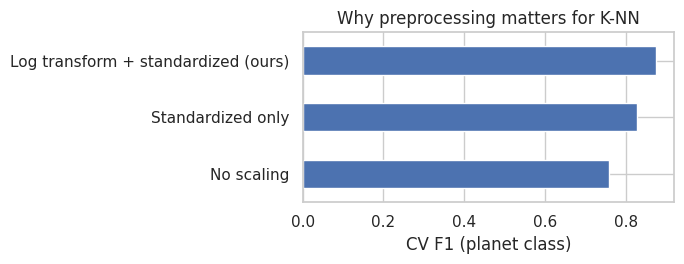

In [20]:
def make_unscaled(features):
    return Pipeline([("prep", ColumnTransformer([("imp", SimpleImputer(strategy="median"), features)])),
                     ("knn", KNeighborsClassifier(n_neighbors=BEST_K, metric=BEST_METRIC, weights=BEST_WEIGHTS))])

def make_scaled_only(features):
    return Pipeline([("prep", ColumnTransformer([("p", Pipeline([("imp", SimpleImputer(strategy="median")),
                                                                  ("sc", StandardScaler())]), features)])),
                     ("knn", KNeighborsClassifier(n_neighbors=BEST_K, metric=BEST_METRIC, weights=BEST_WEIGHTS))])

scal = {
    "No scaling": cv_scores(make_unscaled(ALL_FEATURES)),
    "Standardized only": cv_scores(make_scaled_only(ALL_FEATURES)),
    "Log transform + standardized (ours)": cv_scores(make_knn(k=BEST_K, metric=BEST_METRIC, weights=BEST_WEIGHTS)),
}
scal_df = pd.DataFrame(scal).T.round(4)
display(scal_df)
scal_df["f1"].plot.barh(figsize=(7, 2.8), color="#4C72B0"); plt.xlabel("CV F1 (planet class)")
plt.title("Why preprocessing matters for K-NN"); plt.tight_layout(); plt.show()

**(b) Curse of dimensionality / irrelevant features.** Every extra feature adds to the distance, even if it is pure noise. We append random noise columns and watch K-NN degrade, compared with logistic regression, which can learn to ignore them.

,# noise features,K-NN F1,Logistic regression F1
0,0,0.8759,0.7905
1,5,0.8271,0.7892
2,10,0.7910,0.7865
3,20,0.7637,0.7883
4,40,0.7246,0.7853


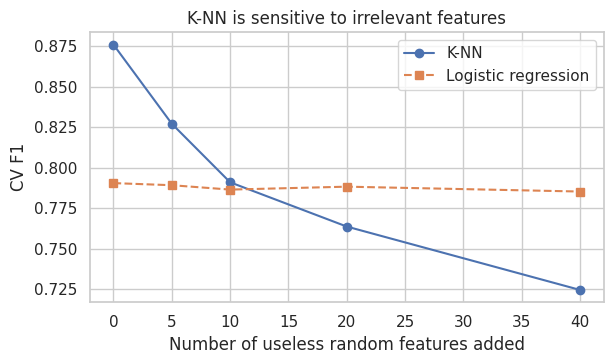

In [21]:
rng = np.random.default_rng(RANDOM_STATE)
noise_counts = [0, 5, 10, 20, 40]
rows = []
for n_noise in noise_counts:
    Xn = X_train.copy()
    noise_cols = [f"noise_{i}" for i in range(n_noise)]
    for c in noise_cols:
        Xn[c] = rng.normal(size=len(Xn))
    feats = ALL_FEATURES + noise_cols
    knn_m = make_knn(features=feats, k=BEST_K, metric=BEST_METRIC, weights=BEST_WEIGHTS)
    lr_m = Pipeline([("prep", make_preprocessor(feats)), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))])
    f_knn = cross_validate(knn_m, Xn[feats], y_train, cv=CV, scoring="f1", n_jobs=-1)["test_score"].mean()
    f_lr = cross_validate(lr_m, Xn[feats], y_train, cv=CV, scoring="f1", n_jobs=-1)["test_score"].mean()
    rows.append((n_noise, f_knn, f_lr))
noise_df = pd.DataFrame(rows, columns=["# noise features", "K-NN F1", "Logistic regression F1"]).round(4)
display(noise_df)
plt.figure(figsize=(6.2, 3.8))
plt.plot(noise_df["# noise features"], noise_df["K-NN F1"], "o-", label="K-NN")
plt.plot(noise_df["# noise features"], noise_df["Logistic regression F1"], "s--", label="Logistic regression")
plt.xlabel("Number of useless random features added"); plt.ylabel("CV F1"); plt.title("K-NN is sensitive to irrelevant features")
plt.legend(); plt.tight_layout(); plt.show()

### 11.5 Cost at prediction time

Because K-NN does its work **when predicting**, speed depends on how neighbors are searched. `brute` compares against every stored point; `kd_tree` and `ball_tree` use a tree to skip most of them.

In [22]:
import time
rows = []
for algo in ["brute", "kd_tree", "ball_tree"]:
    m = Pipeline([("prep", make_preprocessor(ALL_FEATURES)),
                  ("knn", KNeighborsClassifier(n_neighbors=BEST_K, metric=BEST_METRIC, weights=BEST_WEIGHTS, algorithm=algo))])
    t0 = time.perf_counter(); m.fit(X_train, y_train); fit_t = time.perf_counter() - t0
    times = []
    for _ in range(3):
        t0 = time.perf_counter(); m.predict(X_test); times.append(time.perf_counter() - t0)
    rows.append((algo, round(fit_t, 4), round(min(times), 4)))
pd.DataFrame(rows, columns=["search algorithm", "fit time (s)", "predict time (s)"])

,search algorithm,fit time (s),predict time (s)
0,brute,0.0198,0.2212
1,kd_tree,0.0344,0.2279
2,ball_tree,0.0359,0.2326


**Takeaways from the spotlight**
* K-NN = *store the data, vote among the closest `k`* – the from-scratch version reproduces scikit-learn.
* `k` controls the boundary: small → jagged/overfit, large → smooth/underfit.
* Every prediction can be explained by listing its neighbors.
* K-NN needs scaling and clean, relevant features; it degrades quickly when noise features are added.
* Its cost is paid at prediction time, not at training time.

## 12. Bonus: predicting the unresolved `CANDIDATE` objects

These objects have no confirmed label. The model's probability here is the **fraction of the k nearest neighbors that are confirmed planets**. This is a ranking aid, not proof that an object is a planet.

Candidates predicted as planets (p >= 0.5): 859 of 1977


,kepoi_name,planet_probability
230,K00901.01,1.0
184,K00865.01,1.0
304,K00935.04,1.0
7192,K04647.02,1.0
812,K01331.01,1.0
830,K01271.01,1.0
537,K01145.01,1.0
668,K01362.01,1.0
744,K01315.01,1.0
864,K01397.01,1.0


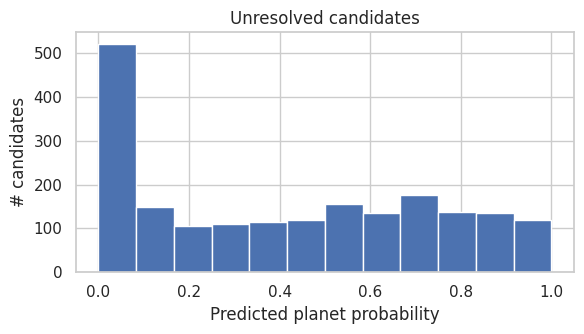

In [23]:
cand_X = candidates[ALL_FEATURES]
cand_proba = best_model.predict_proba(cand_X)[:, 1]
out = candidates[["kepoi_name"]].copy() if "kepoi_name" in candidates.columns else pd.DataFrame(index=candidates.index)
out["planet_probability"] = cand_proba
print("Candidates predicted as planets (p >= 0.5):", int((cand_proba >= 0.5).sum()), "of", len(cand_proba))
display(out.sort_values("planet_probability", ascending=False).head(10).round(3))

plt.figure(figsize=(6, 3.5))
plt.hist(cand_proba, bins=BEST_K + 1)
plt.xlabel("Predicted planet probability"); plt.ylabel("# candidates"); plt.title("Unresolved candidates")
plt.tight_layout(); plt.show()

## 13. Conclusions

1. **Did K-NN beat the baselines?**

   Yes. The optimized K-NN model outperformed both the majority-class baseline and logistic regression. It achieved 91.44% accuracy, 85.35% precision, 92.18% recall, an F1-score of 0.8864 and ROC-AUC of 0.9684 on the test set. It also performed slightly better than baseline K-NN (k=5), which achieved an F1-score of 0.8842. This demonstrates that tuning the K-NN hyperparameters improved its classification performance.

2. **What helped most?**

   Transit-shape features contributed the most to model performance. Removing them reduced cross-validation F1 from 0.8759 to 0.8391. Removing planet, signal and star features also reduced performance. The best configuration used Manhattan distance, uniform weights and k=11. PCA did not improve performance; retaining all original features produced the highest cross-validation F1 of 0.8759. Therefore, keeping the original feature information was more effective than dimensionality reduction in this experiment.

3. **Overfitting and underfitting**

   The validation-curve analysis showed that small values of k can lead to overfitting. At k=1, the train-validation accuracy gap was 0.119. At the selected k=11, the gap reduced to 0.013. This indicates a better balance between memorizing individual observations and generalizing to unseen data. Very large values of k can lead to underfitting because predictions become overly averaged.

4. **Data leakage**

   Features such as `koi_score`, `koi_pdisposition` and `koi_fpflag_*` were excluded because they contain information closely related to NASA's existing disposition or vetting decisions. Including them could allow the model to indirectly access information about the target label, resulting in artificially high performance. Excluding them makes the classification task more meaningful.

5. **What did the K-NN experiments demonstrate?**

   The from-scratch K-NN implementation produced predictions identical to the equivalent scikit-learn Euclidean K-NN implementation on 100% of the test objects. The scaling experiment showed that preprocessing is essential: cross-validation F1 improved from 0.7593 without scaling to 0.8759 with log transformation and standardization. Adding irrelevant features reduced K-NN performance, with F1 falling to 0.7246 after adding 40 noise features. Neighbor-based explanations also demonstrated how individual predictions can be understood through the labels of nearby observations.

6. **Limitations**

   This project uses only the Kepler Objects of Interest dataset, so its results may not generalize to data from other telescopes. The model depends on a fixed set of 11 selected features and is sensitive to feature scaling and irrelevant variables. K-NN can also become computationally expensive when the dataset grows because predictions require finding nearby observations. Additionally, the original classifications are based on an astronomical vetting process and may contain uncertainty.

7. **Future work**

   Future improvements could include experimenting with tree-based algorithms, class-weighting techniques and additional feature engineering. The model could also be tested on newer TESS observations to examine whether it generalizes beyond the Kepler dataset.

**Data citation:** NASA Exoplanet Archive, *Kepler Objects of Interest Cumulative Table*, NExScI-Caltech/IPAC, DOI: 10.26133/NEA4.